# DeepShape2, part 1: simulate → image → facet

**The big goal.** Weak gravitational lensing very slightly stretches the shapes of distant galaxies. DeepShape2 wants to measure
those shapes (the *ellipticity* e1, e2) from radio telescope data. To check whether a method gets the shapes right, you
need data where you **already know the answer**, so the first job is to simulate a sky and simulate what the telescope would record.

This notebook covers only that first half. Every step uses the repo's own functions, called the same way the real scripts call them:

| Step | Repo function(s) | Script that does it for real |
|---|---|---|
| 1. Catalogue → patch of sky | `random_patch`, `filter_patch_by_flux`, `filter_patch_by_size`, `compute_pixel_coordinates` | `scripts/simulations/wide_set.py` |
| 2. Patch → sky image | `simulate_wide_field` | `scripts/simulations/wide_set.py` |
| 3. Sky image → visibilities | `simulate_visibilities` | `scripts/simulations/patch_visibilities.py` |
| 4. Visibilities → dirty image + PSF | `make_dirty_image_and_psf` | (called inside `get_facets`) |
| 5. Visibilities → one small image per galaxy | `get_facets` | `scripts/simulations/facets.py` |

The only differences from the real scripts: the sky is much smaller (so it runs on a laptop), the galaxy catalogue is
made up here because the real one lives on the cluster, and we use the telescope settings the trained networks were made with
(section 1 explains why). At the end the results are saved to a file, which **part 2** (deconvolution, deblending, shape
measurement) picks up.

**Kernel:** use the `deepshape` conda env. The whole notebook runs in about 2 minutes.

## 0. Setup

The first lines are a macOS workaround: numpy and torch each bring their own copy of a threading library (OpenMP), and without
this the kernel crashes. You don't need to understand it, just keep the import order.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import numpy as np
np.linalg.norm(np.ones(2))   # macOS: wake up numpy's maths library before torch loads
import torch                 # noqa: F401  (deepshape2 imports it; it must load before galsim)
import galsim                # noqa: F401

import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams["figure.dpi"] = 110


def show(ax, img, title, cmap="inferno", **kw):
    # Small helper so the plotting code below stays short.
    ax.imshow(img, origin="lower", cmap=cmap, **kw)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

## 1. The config

Every number that has to agree between steps (pixel size, frequency, sky size, ...) lives in one file,
`deepshape2/config/default.yaml`, and every module reads it with `load_config()`. That way the simulation, the imaging and
the neural networks can't silently disagree about, say, how big a pixel is.

In [2]:
from deepshape2.utils import load_config

cfg = load_config()

print(f"pixel size       : {cfg['SCALE_RADIANS'] * 180 / np.pi * 3600:.3f} arcsec")
print(f"NPIX_SKY         : {cfg['NPIX_SKY']} pixels per side ({cfg['NPIX_SKY']**2 * 4 / 1e9:.1f} GB as one image)")
print(f"frequency        : {cfg['frequency'] / 1e6:.0f} MHz, bandwidth {cfg['bandwidth'] / 1e6:.0f} MHz")
print(f"observation      : hour angle {cfg['ha_interval']} h, one sample every {cfg['integration_time']} s")
print(f"pointing (RA,Dec): ({cfg['RA0']}, {cfg['DEC0']}) deg")

pixel size       : 0.100 arcsec
NPIX_SKY         : 25200 pixels per side (2.5 GB as one image)
frequency        : 140 MHz, bandwidth 51 MHz
observation      : hour angle [-4, 4] h, one sample every 300 s
pointing (RA,Dec): (243, 55) deg


### The settings the trained networks expect

The config above is **not** what the trained networks were made with. The networks in `DS2_model_weights/` were trained in
April 2026 on simulations of the **SKA-MID** telescope. In May the config was switched to match real **LOFAR** data
(git history of `default.yaml`: "Modified default config to use ILT values"). The simulator itself still models SKA-MID.

A neural network only works on data that looks like what it was trained on. With the current config, the deconvolution network in
part 2 fails completely (we tried: its result doesn't even fit the data). So for these notebooks we put back the settings from
the time of training:

| setting | config now (LOFAR) | used here (SKA-MID, as trained) | why it matters |
|---|---|---|---|
| frequency | 140 MHz | 1.4 GHz | sets how blurry the image is (section 6 shows this) |
| bandwidth | 50 MHz | 420 MHz (the code's old default, 0.3 × frequency) | more bandwidth = more signal collected = less noise |
| pixel size | 0.100″ | 0.143″ | the networks learned what a galaxy and a PSF look like *in pixels* |
| pointing (RA, Dec) | (243°, +55°) | (56°, −30°) | SKA is in the southern hemisphere; Dec −30° passes straight overhead, which sets the PSF's shape |

Frequency, bandwidth and pointing can be passed straight to the functions. The pixel size can't always: some functions read it
from a variable that was filled in from the config when the module was imported, so we overwrite that variable.

We also shrink the sky to `N = 1024` pixels instead of 25200, so it runs in a couple of minutes instead of hours.

In [3]:
SCALE_RAD = 6.93e-7                       # pixel size in radians (0.143 arcsec), SKA-MID training value
SCALE_DEG = SCALE_RAD * 180 / np.pi
SCALE_ARCSEC = SCALE_DEG * 3600

FREQ = 1.4e9                              # Hz
BANDWIDTH = 0.3 * FREQ                    # Hz
RA, DEC = 56.0, -30.0                     # where the telescope points, in degrees

N = 1024                                  # our sky is N x N pixels
STAMP = 128                               # every per-galaxy image in DeepShape2 is 128 x 128

def use_ska_mid_pixels():
    # The imaging code reads the pixel size from these two module variables, set from the config at import.
    import deepshape2.simulation.visibilities as visibilities_module
    visibilities_module.CELLSIZE = SCALE_RAD
    visibilities_module.SCALE_RADIANS = SCALE_RAD


use_ska_mid_pixels()
print(f"pixel {SCALE_ARCSEC:.3f}″, sky {N} px = {N * SCALE_ARCSEC:.0f}″ across, stamps {STAMP} px = {STAMP * SCALE_ARCSEC:.1f}″")

pixel 0.143″, sky 1024 px = 146″ across, stamps 128 px = 18.3″


## 2. The catalogue: the "answer key"

Everything starts from a **catalogue**: a table with one row per galaxy giving where it is, how bright it is, how big it is,
and its true shape. Every later step is compared against this table.

The real pipeline uses **T-RECS**, a big published simulation of the radio sky. `deepshape2/data/trecs.py` converts its FITS
file into a pandas table (`catalog_wide.pkl` on the cluster). That file isn't on this laptop, so we build a small table **with the same
columns**:

| column | meaning |
|---|---|
| `x`, `y` | position on the sky, in degrees from the field centre |
| `flux` | total brightness in Jansky (Jy). Ours are 5 to 200 µJy (1 µJy = 1e-6 Jy) |
| `size` | how spread out the galaxy is, in arcsec (GalSim's half-light radius is `1.68 × size`) |
| `e1`, `e2` | the ellipticity, i.e. the shape we ultimately want to measure. (0, 0) is round, +e1 is stretched along x, +e2 along the diagonal |

We also place one galaxy deliberately right next to another so that we have a guaranteed **blend** (two galaxies overlapping) to look at.

In [4]:
rng = np.random.default_rng(1)
side_deg = N * SCALE_DEG     # width of our sky in degrees
n_random = 80

catalogue = pd.DataFrame({
    "x": rng.uniform(-side_deg / 2, side_deg / 2, n_random),
    "y": rng.uniform(-side_deg / 2, side_deg / 2, n_random),
    "flux": 10 ** rng.uniform(np.log10(5e-6), np.log10(200e-6), n_random),
    "size": rng.uniform(0.3, 1.0, n_random),
    "e1": np.clip(rng.normal(0, 0.25, n_random), -0.7, 0.7),
    "e2": np.clip(rng.normal(0, 0.25, n_random), -0.7, 0.7),
})

# A deliberate blend: a target galaxy and a fainter neighbour about 2 arcsec away.
pair = pd.DataFrame({
    "x": [0.004, 0.004 + 12 * SCALE_DEG],
    "y": [-0.004, -0.004 + 8 * SCALE_DEG],
    "flux": [80e-6, 20e-6],
    "size": [0.7, 0.5],
    "e1": [0.3, -0.2],
    "e2": [0.1, 0.25],
})
catalogue = pd.concat([catalogue, pair], ignore_index=True)
TARGET, NEIGHBOUR = n_random, n_random + 1    # row labels of the pair

catalogue.tail()

,x,y,flux,size,e1,e2
77,0.017040,-0.004371,0.000113,0.709476,0.192658,-0.221220
78,0.013288,-0.010901,0.000160,0.345709,-0.027911,-0.002347
79,0.015675,0.013874,0.000005,0.336523,-0.064416,-0.380589
80,0.004000,-0.004000,0.000080,0.700000,0.300000,0.100000
81,0.004476,-0.003682,0.000020,0.500000,-0.200000,0.250000


## 3. Cut out a patch and convert to pixels

These four calls are copied from `wide_set.py`. Each one has a reason:

* **`random_patch`** keeps the galaxies inside a square of sky, **and drops any within 130 px of the edge**. Later we cut a
  128×128 image around every galaxy, and a galaxy near the edge wouldn't have room.
* **`filter_patch_by_flux`** keeps galaxies between 1 and 200 µJy (its defaults), the brightness range the method is built for.
* **`filter_patch_by_size`** drops galaxies bigger than 6″, which wouldn't fit in a 128-pixel (18″) stamp.
* **`compute_pixel_coordinates`** turns degrees into pixel positions `pix_x`, `pix_y`. We pass `NPIX_SKY=N` because our sky is
  N wide, not 25200. It also returns the RA/Dec of the patch centre, worked out from the config's (LOFAR) pointing, so we
  ignore that and keep our SKA-MID pointing.

We pass our pixel size to each of these explicitly (`pixel_scale_degrees=`, `scale=`).

In [6]:
from deepshape2.simulation import (
    compute_pixel_coordinates,
    filter_patch_by_flux,
    filter_patch_by_size,
    random_patch,
)

centre_flat = (0.0, 0.0)   # flat-sky position of our patch, in degrees

patch = random_patch(centre_flat, catalogue=catalogue, patch_size_degrees=side_deg, pixel_scale_degrees=SCALE_DEG)
print(f"{len(catalogue)} galaxies in catalogue -> {len(patch)} after the edge cut")

patch = filter_patch_by_size(filter_patch_by_flux(patch))
print(f"-> {len(patch)} after the flux and size cuts")

patch, _ = compute_pixel_coordinates(patch, centre_flat, scale=SCALE_DEG, NPIX_SKY=N)

patch.head()

82 galaxies in catalogue -> 54 after the edge cut
-> 54 after the flux and size cuts


,flux,size,e1,e2,pix_x,pix_y
0,0.000021,0.382674,-0.091567,-0.048451,524,676
2,0.000050,0.365511,-0.350330,0.047186,148,786
4,0.000034,0.482255,-0.416872,-0.216382,320,851
6,0.000022,0.501830,-0.020249,-0.343242,847,845
7,0.000161,0.368401,-0.160489,-0.137953,420,169


## 4. Draw the sky: `simulate_wide_field`

For each galaxy, GalSim draws a smooth **Sérsic** profile (a standard galaxy light profile) with the catalogue's flux and size,
stretches it by (e1, e2), and adds it into one big N×N image at (`pix_x`, `pix_y`). Pixel values are in Jy per pixel.

It returns three things, and the reason there are three is the whole point of simulating:

1. **`sky`**: all galaxies together, overlapping where they're close. This is what the telescope sees.
2. **`patch_out`**: the table again, plus the `sersic_index` that was used and a `flux_mask` column.
3. **`isolated_stamps`**: for every galaxy brighter than `min_flux`, a 128×128 image of **that galaxy alone, with no neighbours,
   no telescope, no noise**. This is the perfect answer the rest of the pipeline is trying to recover.

`flux_mask` marks which galaxies got a stamp. Fainter ones are still drawn into the sky (real skies have them, and their light
gets in the way) but are too faint to measure, so they get no stamp and no facet. We use `min_flux=10e-6` like `wide_set.py`.

sky: (1024, 1024)   total flux 2848 µJy
isolated_stamps: (46, 128, 128)  <- one per bright galaxy, same order as `bright`
46 bright, 8 faint


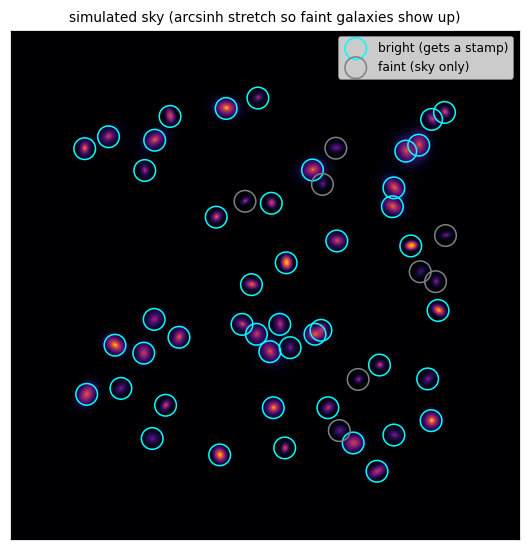

In [8]:
from deepshape2.simulation import simulate_wide_field

sky, patch_out, isolated_stamps = simulate_wide_field(
    patch, NPIX_SKY=N, min_flux=10e-6, npix_stamp=STAMP, scale=SCALE_ARCSEC
)

bright = patch_out[patch_out["flux_mask"]]   # the galaxies we will actually measure
print("sky:", sky.shape, f"  total flux {sky.sum() * 1e6:.0f} µJy")
print("isolated_stamps:", isolated_stamps.shape, " <- one per bright galaxy, same order as `bright`")
print(f"{len(bright)} bright, {len(patch_out) - len(bright)} faint")

fig, ax = plt.subplots(figsize=(6, 6))
show(ax, np.arcsinh(sky / 1e-8), "simulated sky (arcsinh stretch so faint galaxies show up)")
faint = patch_out[~patch_out["flux_mask"]]
ax.scatter(bright["pix_x"], bright["pix_y"], s=200, facecolors="none", edgecolors="cyan", label="bright (gets a stamp)")
ax.scatter(faint["pix_x"], faint["pix_y"], s=200, facecolors="none", edgecolors="grey", label="faint (sky only)")
ax.legend(loc="upper right", fontsize=8);

### Isolated vs blended stamps

`wide_set.py` also cuts a 128×128 **blended stamp** out of the sky around each bright galaxy (`centers_to_limits` gives the
crop boxes). Comparing the two for our deliberate pair shows the **deblending** problem: the blended stamp contains the
neighbour's light too, but the shape we want is the isolated galaxy's.

true shape of target: e1=0.30 e2=0.10


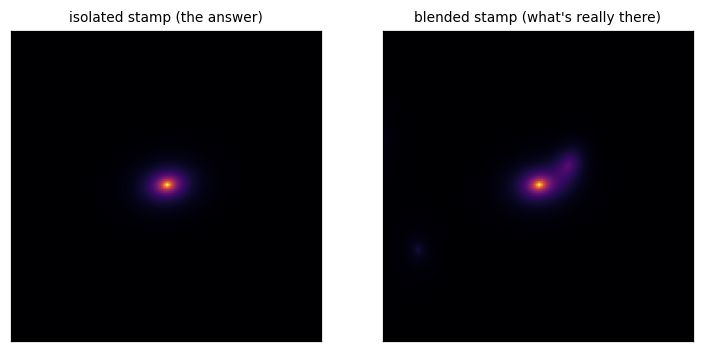

In [9]:
from deepshape2.utils import centers_to_limits

centres = bright[["pix_x", "pix_y"]].values
limits = centers_to_limits(centres, stamp_size=STAMP)
blended_stamps = np.stack([sky[y0:y1, x0:x1] for x0, x1, y0, y1 in limits])

i_target = bright.index.get_loc(TARGET)   # position of our target galaxy in `bright`

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
show(ax[0], isolated_stamps[i_target], "isolated stamp (the answer)")
show(ax[1], blended_stamps[i_target], "blended stamp (what's really there)")
print("true shape of target: e1=%.2f e2=%.2f" % tuple(bright.loc[TARGET, ["e1", "e2"]]))

## 5. Visibilities: what a radio interferometer actually records

A radio interferometer **doesn't take a picture**. It's many antennas (SKA-MID: ~200), and the signals of every *pair* of
antennas are combined. Each pair, at each moment, measures **one number**: one Fourier component of the sky image, i.e. how much
of one particular ripple pattern is in the sky. Which ripple depends on how far apart the two antennas are and in which direction,
measured in wavelengths. That separation is called (u, v), and the measured complex number is a **visibility**.

As the Earth rotates, every pair's (u, v) slowly changes, so an 8-hour observation fills in more of the Fourier plane. It never
fills it completely, though, and **the gaps are why radio images come out blurred with ripples** (next section).

`simulate_visibilities` does exactly what `patch_visibilities.py` does for each patch:

1. `predict_visibilities_from_array`: sky image → the visibilities SKA-MID would measure (observation length and timing from the
   config, frequency and bandwidth from us)
2. `add_noise_to_visibility`: adds random **thermal noise**, set by SKA-MID's sensitivity (receivers are never perfectly quiet)

The noise on each single visibility is about 0.6 mJy, far more than any of our galaxies (≤ 0.2 mJy)! That's normal: the image
combines ~2 million visibilities, and averaging beats the noise down to under 1 µJy (we measure it in section 6).

The script also passes `filename=...` to save a `.ms` (Measurement Set, the standard radio data file). We keep everything in memory.

In [11]:
from deepshape2.simulation import simulate_visibilities

t = time.time()
vis = simulate_visibilities(sky, RA, DEC, frequency=FREQ, channel_bandwidth=BANDWIDTH, threads=8)
print(f"took {time.time() - t:.0f} s")

n_time, n_baseline, n_chan, n_pol = vis.vis.shape
print(f"vis.vis has shape {vis.vis.shape}:")
print(f"  {n_time} time steps x {n_baseline} antenna pairs x {n_chan} frequency x {n_pol} polarisation")
print(f"  = {vis.vis.size / 1e6:.1f} million complex numbers. That's the raw data.")

took 5 s
vis.vis has shape (96, 19503, 1, 1):
  96 time steps x 19503 antenna pairs x 1 frequency x 1 polarisation
  = 1.9 million complex numbers. That's the raw data.


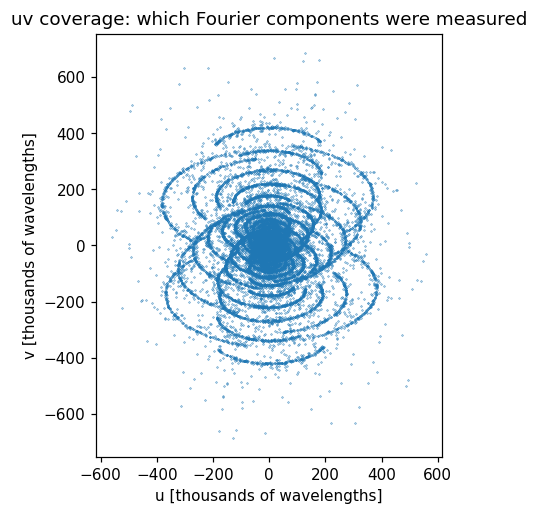

In [12]:
uvw = np.asarray(vis.visibility_acc.uvw_lambda)[:, :, 0, :].reshape(-1, 3)   # (u, v, w) in wavelengths
sel = np.random.default_rng(0).choice(len(uvw), 30000, replace=False)       # plot a subset, it's a lot of points

fig, ax = plt.subplots(figsize=(5, 5))
# each pair measures the point (u, v) AND its mirror (-u, -v) for free, so we plot both
ax.scatter(uvw[sel, 0] / 1e3, uvw[sel, 1] / 1e3, s=0.1, c="C0")
ax.scatter(-uvw[sel, 0] / 1e3, -uvw[sel, 1] / 1e3, s=0.1, c="C0")
ax.set(title="uv coverage: which Fourier components were measured", xlabel="u [thousands of wavelengths]",
       ylabel="v [thousands of wavelengths]", aspect="equal");

## 6. Imaging: the dirty image and the PSF

The obvious way to get a picture back is to put the visibilities on a grid and inverse-Fourier-transform. The result is the
**dirty image**: "dirty" because the missing (u, v) points leave blur and ripples in it.

The **PSF** (point spread function, also called the *dirty beam*) is the dirty image you'd get if the sky were **one single point
of light** at the centre, observed with the same (u, v) coverage. It's the telescope's blur pattern. The key relation, which the whole of
DeepShape2 is built around, is

$$\text{dirty image} = \text{true sky} \circledast \text{PSF} + \text{noise}$$

(⊛ = convolution: every point of the sky gets replaced by a copy of the PSF). That's why **every later step gets the PSF together
with the dirty image**: deconvolution (HQS-PnP) needs it to undo the blur, and the shape network needs it to know how the blur
distorted the shape.

`make_dirty_image_and_psf` does the gridding + inverse FFT and returns both. It uses "robust" weighting by default, a standard
compromise between sharpness and noise.

You may see `warning ... skipped N visibility`: a handful of the very longest baselines (out of ~2 million) measure finer detail than one 0.143″ pixel can show, so the imager leaves them out. Harmless.

warning visibility_weight_to_griddata gridding: skipped 13 visbility


PSF peak value: 1.0 (normalised to 1 at the centre)


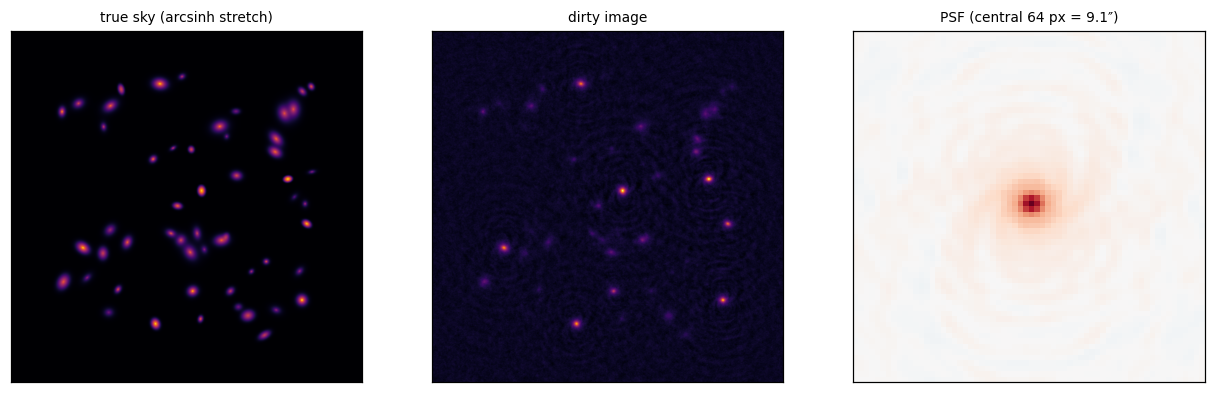

In [14]:
from deepshape2.simulation import make_dirty_image_and_psf

dirty_full, psf_full = make_dirty_image_and_psf(vis, NPIX=N, do_wstacking=True, threads=8)

c = N // 2
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
show(ax[0], np.arcsinh(sky / 1e-8), "true sky (arcsinh stretch)")
show(ax[1], dirty_full, "dirty image")
show(ax[2], psf_full[c - 32:c + 32, c - 32:c + 32], f"PSF (central 64 px = {64 * SCALE_ARCSEC:.1f}″)", cmap="RdBu_r", vmin=-1, vmax=1)
print("PSF peak value:", psf_full.max(), "(normalised to 1 at the centre)")

In [22]:
from ska_sdp_func_python.imaging import invert_ng
import inspect

help(inspect.getsource(invert_ng))

No Python documentation found for 'def invert_ng(\n    bvis: Visibility,\n    model: Image,\n    dopsf: bool = False,\n    normalise: bool = True,\n    **kwargs,\n) -> (Image, numpy.ndarray):\n    """Invert using nifty-gridder module.\n\n     https://gitlab.mpcdf.mpg.de/ift/nifty_gridder\n\n    Use the Image im as a template. Do PSF in a separate call.\n\n    In the imaging and pipeline workflows,\n    this may be invoked using context=\'ng\'. It is the default.\n\n    :param dopsf: Make the PSF instead of the dirty image\n    :param bvis: Visibility to be inverted\n    :param im: Image template (not changed)\n    :param normalise: Normalise by the sum of weights (True)\n    :return: (resulting Image, sum of the weights for\n                each frequency and polarization)\n\n    """\n\n    # Make sure we are dealing with an Image\n    assert isinstance(model, Image), model\n    assert model.image_acc.is_canonical()\n\n    im = model.copy(deep=True)\n\n    nthreads = kwargs.get("thread

### Check: is the dirty image really sky ⊛ PSF?

Let's convolve the true sky with the PSF ourselves (an FFT product, the same calculation `calculate_dirty_peak` in
`deepshape2/utils/images.py` uses) and subtract it from the dirty image. If the relation holds, what's left is mostly the noise.
It won't be perfect, because our PSF image is only as big as the sky and so misses the PSF's far ripples, but it should be close.

noise in the dirty image: 0.71 µJy/beam


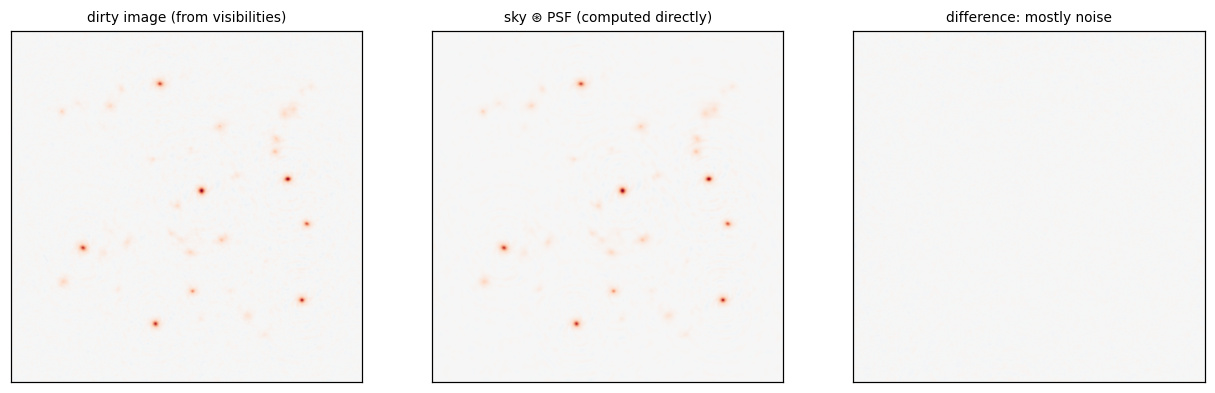

In [23]:
from numpy.fft import ifftshift, irfft2, rfft2

sky_conv_psf = irfft2(rfft2(sky) * rfft2(ifftshift(psf_full)), s=sky.shape)
residual = dirty_full - sky_conv_psf

noise_rms = 1.4826 * np.median(np.abs(residual - np.median(residual)))   # robust standard deviation
print(f"noise in the dirty image: {noise_rms * 1e6:.2f} µJy/beam")

lim = np.abs(dirty_full).max()
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
show(ax[0], dirty_full, "dirty image (from visibilities)", vmin=-lim, vmax=lim, cmap="RdBu_r")
show(ax[1], sky_conv_psf, "sky ⊛ PSF (computed directly)", vmin=-lim, vmax=lim, cmap="RdBu_r")
show(ax[2], residual, "difference: mostly noise", vmin=-lim, vmax=lim, cmap="RdBu_r")

### Why frequency matters: the PSF gets wider at low frequency

The PSF only depends on **where in (u, v) we measured**, not on what's in the sky, so we can compute it from an empty
visibility template (`create_visibility_template`). The (u, v) positions are measured in wavelengths, so 10× lower frequency
means 10× longer wavelength, 10× smaller (u, v), and a 10× wider PSF.

warning visibility_weight_to_griddata gridding: skipped 22 visbility


each panel is 18″ across; our galaxies are roughly 1″


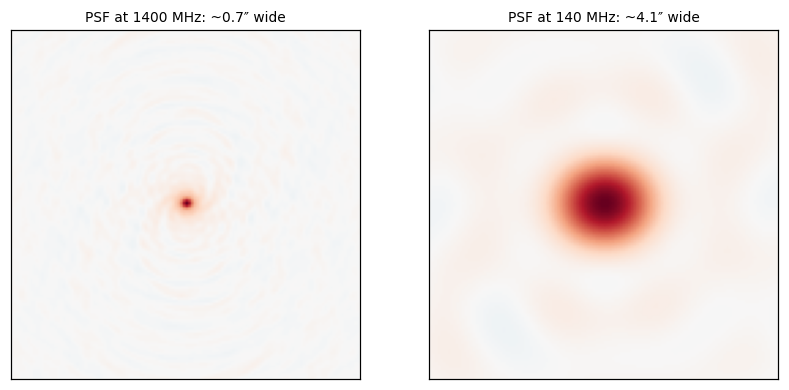

In [24]:
from astropy import units as u
from astropy.coordinates import SkyCoord

from deepshape2.simulation import create_visibility_template

phasecentre = SkyCoord(RA * u.deg, DEC * u.deg)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
for a, f in zip(ax, [FREQ, cfg["frequency"]]):
    empty_vis = create_visibility_template(phasecentre, frequency=f)
    psf = make_dirty_image_and_psf(empty_vis, NPIX=256, do_dirty=False, do_wstacking=False, threads=8)
    fwhm_arcsec = (psf[128] > 0.5).sum() * SCALE_ARCSEC     # width where the PSF is above half its peak
    show(a, psf[64:192, 64:192], f"PSF at {f / 1e6:.0f} MHz: ~{fwhm_arcsec:.1f}″ wide", cmap="RdBu_r", vmin=-1, vmax=1)
print(f"each panel is {128 * SCALE_ARCSEC:.0f}″ across; our galaxies are roughly 1″")

## 7. Faceting: one small image per galaxy

**Why not just cut stamps out of the big dirty image?** In the real pipeline the field is 25200×25200 pixels with thousands of
galaxies. Imaging all of it at once is 2.5 GB per image and slow, and the neural networks downstream only ever look at a
**128×128 image centred on one galaxy, plus the PSF for that galaxy**. So for every galaxy DeepShape2 makes a small **facet**
straight from the visibilities, and each facet can be computed independently, in parallel.

**How do you centre an image on a galaxy without the big image?** By the Fourier shift theorem: shifting the sky in position
is the same as multiplying every visibility by a phase factor $e^{-2\pi i (u\,\Delta l + v\,\Delta m)}$. Changing where the
telescope "points" after the fact like this is called **phase rotation**, and `rephase_visibility` does it. Imaging the
rephased visibilities with only 128×128 pixels then gives a dirty facet with the galaxy exactly at the centre, plus its PSF.

### One facet by hand

Two practical details:
* `rephase_visibility` and `get_facets` take pixel positions in the **25200-pixel frame** (they measure the offset from pixel 12600).
  Our sky is only N wide, so we add an offset that puts our sky in the middle of that frame.
* `rephase_visibility` **modifies the visibilities you pass in** (it multiplies the data in place). So we hand it a copy.

warning visibility_weight_to_griddata gridding: skipped 33 visbility


old phase centre: 56.00000 -30.00000
new phase centre: 55.99541 -30.00397
brightest pixel of the facet: (64, 64) (the centre is (64, 64))


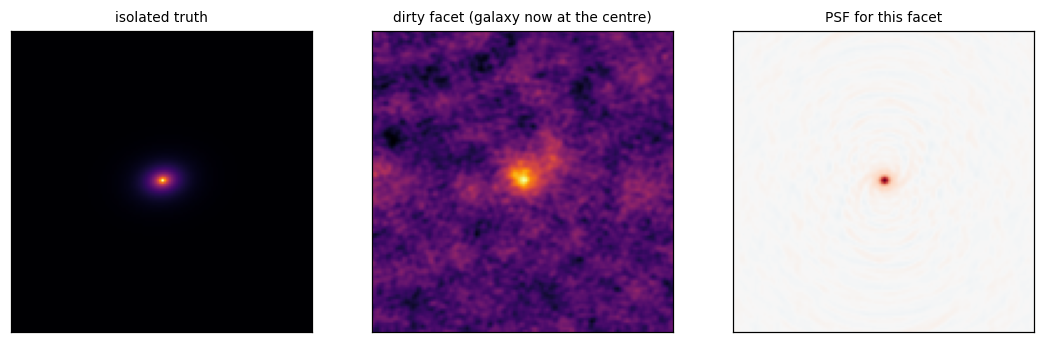

In [25]:
from deepshape2.simulation import rephase_visibility

OFFSET = cfg["NPIX_SKY"] // 2 - N // 2     # our pixel -> 25200-frame pixel

x, y = bright.loc[TARGET, ["pix_x", "pix_y"]]
vis_target = rephase_visibility(vis.copy(deep=True), (x + OFFSET, y + OFFSET))
dirty_facet, psf_facet = make_dirty_image_and_psf(vis_target, NPIX=STAMP, do_wstacking=False, threads=8)

print("old phase centre:", vis.attrs["phasecentre"].to_string("decimal", precision=5))
print("new phase centre:", vis_target.attrs["phasecentre"].to_string("decimal", precision=5))
print("brightest pixel of the facet:", np.unravel_index(dirty_facet.argmax(), dirty_facet.shape), "(the centre is (64, 64))")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
show(ax[0], isolated_stamps[i_target], "isolated truth")
show(ax[1], dirty_facet, "dirty facet (galaxy now at the centre)")
show(ax[2], psf_facet, "PSF for this facet", cmap="RdBu_r", vmin=-1, vmax=1)

### All facets with `get_facets`

`get_facets` does the same for a list of positions, in parallel with dask. We start a small local dask cluster with
**separate processes**, like `facets.py` does. That's for speed, and it also matters for correctness here: each worker process
gets its own copy of `vis`, so the in-place modification above can't make facets interfere with each other.
(With dask's default *threads* every facet would share one `vis` and the results come out wrong.) Each worker is a fresh Python,
so we run a small setup function on it first.

The flip side of every task getting its own copy is memory: the visibilities are ~150 MB, and `get_facets` sends `batch_size`
tasks at once. `facets.py` uses 64 tasks and 64 workers on a big cluster node; on a 16 GB laptop that runs out of memory, so we
use 8 tasks at a time and 2 workers. (More workers doesn't help here anyway: most of the time goes into copying the visibilities.)

In [26]:
from dask.distributed import Client, LocalCluster

from deepshape2.reconstruction import get_facets

locations = bright[["pix_x", "pix_y"]].values + OFFSET

def setup_worker():
    # Each worker is a fresh Python process, so it needs the same two fixes as this notebook:
    import numpy as np
    np.linalg.norm(np.ones(2))   # the macOS numpy-before-torch workaround from Setup
    import torch  # noqa: F401
    use_ska_mid_pixels()         # and our pixel size

t = time.time()
with LocalCluster(n_workers=2, threads_per_worker=1, processes=True, memory_limit=0) as cluster, Client(cluster) as client:
    client.run(setup_worker)
    # the client is picked up automatically. (Passing client=client also works on the Linux cluster, but its
    # memory-cleanup step only exists on Linux, so on a Mac we leave it out.)
    dirty, psf = get_facets(vis, locations, NPIX_facet=STAMP, batch_size=8)
print(f"dirty {dirty.shape}, psf {psf.shape}  in {time.time() - t:.0f} s")

2026-10-22 12:48:01,652 - distributed.nanny - ERROR - Worker process died unexpectedly


Finished processing batch 1/6. Time elapsed: 00:00:38
Finished processing batch 2/6. Time elapsed: 00:01:17
Finished processing batch 3/6. Time elapsed: 00:01:56
Finished processing batch 4/6. Time elapsed: 00:02:35
Finished processing batch 5/6. Time elapsed: 00:03:13
Finished processing batch 6/6. Time elapsed: 00:03:43
dirty (46, 128, 128), psf (46, 128, 128)  in 236 s


Now we have, for every bright galaxy, everything the rest of DeepShape2 uses. Each row below is one galaxy:

* **isolated truth**: what we want to recover
* **blended truth**: the noise-free, unblurred sky around it, neighbours included
* **dirty facet**: what the telescope gives us (blurred, noisy, neighbours included)
* **PSF facet**: the blur, needed to interpret the dirty facet

Look at the target/neighbour pair: both facets contain both galaxies, just centred differently. And compare with the S/N
table below: the faintest galaxies are barely visible in their dirty facets, which is exactly why the later steps are hard.

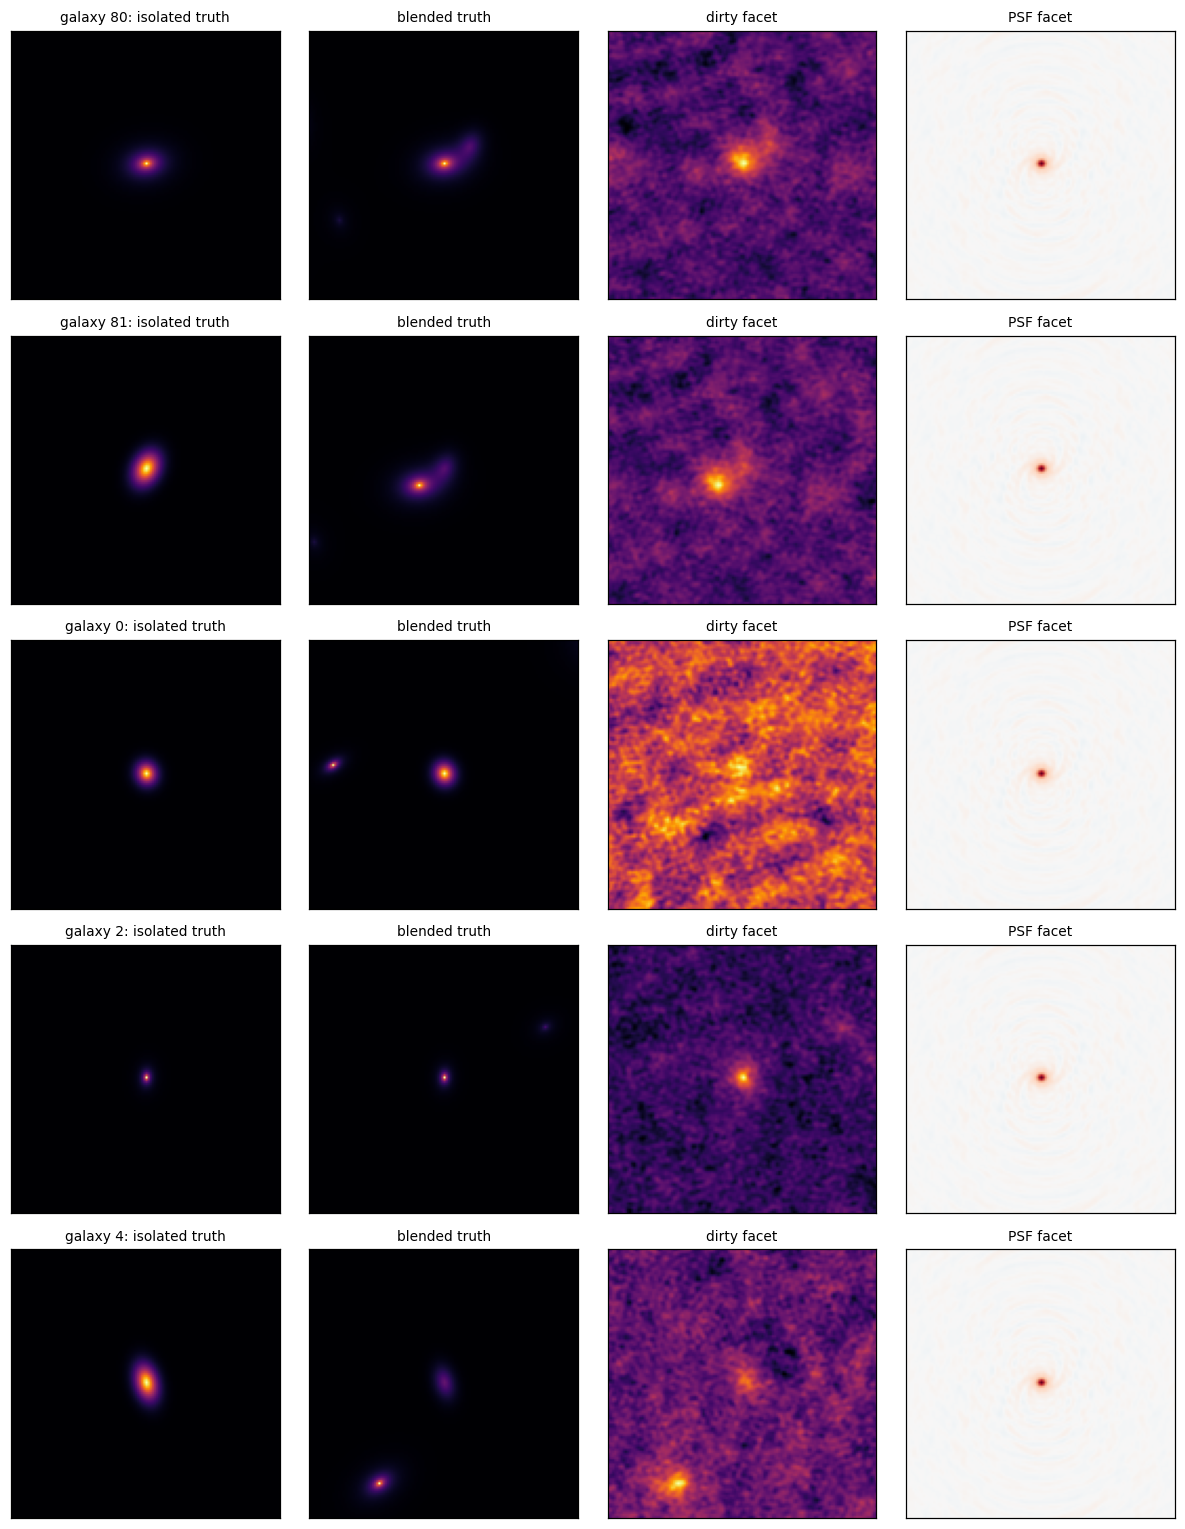

In [27]:
rows = [i_target, bright.index.get_loc(NEIGHBOUR)] + [i for i in range(len(bright)) if bright.index[i] not in (TARGET, NEIGHBOUR)][:3]

fig, ax = plt.subplots(len(rows), 4, figsize=(11, 2.8 * len(rows)))
for r, i in enumerate(rows):
    label = bright.index[i]
    show(ax[r, 0], isolated_stamps[i], f"galaxy {label}: isolated truth")
    show(ax[r, 1], blended_stamps[i], "blended truth")
    show(ax[r, 2], dirty[i], "dirty facet")
    show(ax[r, 3], psf[i], "PSF facet", cmap="RdBu_r", vmin=-1, vmax=1)
plt.tight_layout()

### How detectable is each galaxy? `calculate_dirty_peak`

`facets.py` stores one more number per galaxy: the **peak** brightness the galaxy would have in the dirty image **if it were alone and
noise-free** (isolated stamp ⊛ PSF, then take the maximum). Dividing by the noise from section 6 gives a signal-to-noise ratio.
That tells you which galaxies have enough signal for their shape to be measured at all, so it's used to select galaxies and to judge
results by brightness.

In [28]:
from deepshape2.utils import calculate_dirty_peak

peaks = calculate_dirty_peak(isolated_stamps, psf)
summary = bright[["flux", "size", "e1", "e2"]].copy()
summary["flux"] *= 1e6
summary = summary.rename(columns={"flux": "flux [µJy]", "size": "size [″]"})
summary["peak [µJy/beam]"] = peaks * 1e6
summary["S/N"] = peaks / noise_rms
summary.round(2).sort_values("S/N", ascending=False)

,flux [µJy],size [″],e1,e2,peak [µJy/beam],S/N
51,174.40,0.32,0.30,0.09,47.080002,65.930000
26,199.28,0.37,-0.27,-0.03,46.209999,64.720001
78,159.55,0.35,-0.03,-0.00,44.779999,62.709999
7,160.84,0.37,-0.16,-0.14,38.919998,54.509998
18,180.11,0.45,0.12,-0.30,37.669998,52.750000
73,170.85,0.48,0.28,-0.06,36.020000,50.439999
44,119.89,0.32,0.14,-0.28,32.770000,45.889999
30,97.79,0.39,0.05,0.08,24.450001,34.250000
2,50.20,0.37,-0.35,0.05,13.190000,18.469999
42,92.74,0.74,0.21,0.15,12.550000,17.570000


## Recap: what each step produced, and where it goes next

| Product | Made by | Used later for |
|---|---|---|
| `patch_out` (catalogue + `e1`, `e2`) | `simulate_wide_field` | the true shapes to compare measurements against |
| `isolated_stamps` | `simulate_wide_field` | the target images when training the deconvolver and deblender |
| `blended_stamps` | crop of `sky` | the deconvolution target before deblending |
| `dirty`, `psf` (one pair per galaxy) | `get_facets` | the **input** to everything that follows: HQS-PnP deconvolution, then the VAE deblender, then shape measurement |
| `peaks` | `calculate_dirty_peak` | signal-to-noise, for selecting and judging galaxies |

On the cluster, `wide_set.py`, `patch_visibilities.py` and `facets.py` do exactly these steps for 25200-pixel patches and save
everything into `.h5` files, which the training and reconstruction scripts then read.

### Things to try
* Set `FREQ = cfg["frequency"]` in section 1 and re-run: the galaxies turn into round blobs. (Re-run the save cell only if you
  want part 2 to see that, and expect the networks to struggle.)
* Move the neighbour closer, or make it brighter, in section 2 and compare the target's facet.
* Pass `sigma=...` (noise per visibility in µJy) or `ha_interval=[-1, 1]` (a shorter observation) to `simulate_visibilities`
  and watch the uv coverage, the PSF and the S/N change.

### Save for part 2

`facets.py` writes all of this into an `.h5` file per patch. We do the same with a simple `.npz` file next to this notebook,
which `deepshape2_part2_deconvolve_deblend_shape.ipynb` loads.

In [17]:
np.savez(
    "part1_facets.npz",
    dirty=dirty, psf=psf,
    isolated_stamps=isolated_stamps, blended_stamps=blended_stamps,
    peaks=peaks, noise_rms=noise_rms, scale_arcsec=SCALE_ARCSEC,
    target=TARGET, neighbour=NEIGHBOUR, galaxy_id=bright.index.values,
    **{col: bright[col].values for col in ["flux", "size", "e1", "e2", "sersic_index", "pix_x", "pix_y"]},
)
print("saved part1_facets.npz with", len(dirty), "galaxies")

saved part1_facets.npz with 46 galaxies
